# PY-2 · Model: what wait standard keeps members from abandoning?

**Business question.** Abandonment doubled in May–Jun, and nearly all of the increase came from long phone waits. Operations needs a **wait standard to staff to**, not just a target on the *average*. Leadership's 65-second average-wait target was met every month while 1 in 5 hot-spot callers hung up.

> At what wait does abandonment risk rise sharply, and how many abandoned contacts per month would be avoided by holding phone waits under that standard?

**Why this model (and not another):**
- The outcome is binary (abandoned or not) and the main driver is continuous (wait), so **logistic regression** is the natural choice. It gives interpretable probabilities and confidence intervals, which is what a staffing decision needs.
- Wait enters as a **natural cubic spline**, so the shape (flat, then a threshold) is learned from the data rather than assumed to be a straight line.
- Forecasting was ruled out: there are only 6 monthly points and a structural break, so a forecast would be unreliable. Classifying individual contacts for intervention is not actionable either: you cannot intervene on one caller before they abandon. Segmentation does not answer a staffing question.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "python"))
import tcu_common as tc
FIG = ROOT / "outputs" / "python"; FIG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#9a9893", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True,
                     "axes.grid.axis": "y", "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9.5,
                     "lines.linewidth": 2})

raw = tc.load_raw(ROOT / "data" / "BI_Analyst_Round_1_Technical_Assessment.xlsx")
a, _ = tc.clean(raw)
df = a.dropna(subset=["wait_seconds"]).copy()           # 7 rows without wait excluded
df["may_jun"] = (df.period == "2) May-Jun").astype(int)
print(f"Modeling rows: {len(df):,} | abandoned: {df.is_abandoned.sum()} ({df.is_abandoned.mean():.1%})")
print("Contacts with wait > 120s by period:", df[df.wait_seconds > 120].groupby("period").size().to_dict())

Modeling rows: 3,985 | abandoned: 194 (4.9%)
Contacts with wait > 120s by period: {'1) Jan-Apr': 2, '2) May-Jun': 200}


**Important data caveat before modeling.** Almost every wait over 120s happened in May–Jun, in the hot spot (Jan–Apr had only 2). This creates two problems:
1. **Confounding.** "Long wait" and "hot spot in May–Jun" overlap, so a naive model cannot tell whether abandonment rises because of the wait or because of something else that happened to that queue in May. Model C below controls for this.
2. **Validation.** A clean out-of-time test (train on Jan–Apr, test on May–Jun) cannot work for the threshold region, because the training period has no long waits to learn from. We use stratified cross-validation instead, and run the out-of-time test only to show that limitation explicitly.

## 1 · Three candidate models

In [2]:
FORMULAS = {
    "A  Context only (no wait)":         "is_abandoned ~ C(channel) + C(product) + C(reason) + C(segment) + C(digital_adoption_band)",
    "B  Wait spline only":               "is_abandoned ~ cr(wait_seconds, df=4)",
    "C  Wait spline + context + hot-spot x period":
        "is_abandoned ~ cr(wait_seconds, df=4) + C(channel) + C(product) + C(reason) + C(segment)"
        " + C(digital_adoption_band) + hotspot * may_jun",
}

def cv_scores(formula, data, k=5, seed=7):
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    aucs, briers = [], []
    for tr, te in skf.split(data, data.is_abandoned):
        m = smf.logit(formula, data=data.iloc[tr]).fit(disp=0, maxiter=200)
        p = m.predict(data.iloc[te])
        aucs.append(roc_auc_score(data.is_abandoned.iloc[te], p))
        briers.append(brier_score_loss(data.is_abandoned.iloc[te], p))
    return np.mean(aucs), np.std(aucs), np.mean(briers)

base_brier = brier_score_loss(df.is_abandoned, np.full(len(df), df.is_abandoned.mean()))
rows = []
for name, f in FORMULAS.items():
    auc, sd, br = cv_scores(f, df)
    rows.append({"model": name, "CV AUC (mean)": auc, "CV AUC (sd)": sd, "CV Brier": br,
                 "Brier skill vs base rate": 1 - br / base_brier})
comparison = pd.DataFrame(rows).round(3)
comparison.to_csv(FIG / "py2_model_comparison.csv", index=False)
comparison

,model,CV AUC (mean),CV AUC (sd),CV Brier,Brier skill vs base rate
0,A Context only (no wait),0.607,0.051,0.046,0.004
1,B Wait spline only,0.660,0.051,0.044,0.046
2,C Wait spline + context + hot-spot x period,0.652,0.051,0.044,0.047


**Reading the scores.**
- **AUC** measures how well the model ranks abandoners above non-abandoners (0.5 is random).
- **Brier skill** is the improvement in probability accuracy over guessing the base rate for everyone.

Context alone (A) has only weak signal (AUC about 0.61), mostly because product and reason partly identify the hot-spot queue. Wait alone (B) does better (about 0.66 AUC and 10× the Brier skill). Adding context and the hot-spot × period interaction (C) adds nothing on top of wait, so **wait carries the predictive signal, not who the member is or what they called about.** Overall discrimination is modest (AUC about 0.65). Abandonment is rare below 90s and close to random there, so the model is useful for the *threshold*, not for picking out individual callers.

## 2 · Does the wait effect survive inside the hot spot alone?

In [3]:
hs = df[(df.hotspot == 1) & (df.may_jun == 1)]
band = pd.cut(hs.wait_seconds, [0, 90, 120, 150, 400], labels=["<=90", "91-120", "121-150", "150+"])
within = hs.groupby(band, observed=True).is_abandoned.agg(contacts="size", abandonment_rate="mean").round(3)
within

,contacts,abandonment_rate
wait_seconds,,
<=90,38,0.079
91-120,54,0.167
121-150,89,0.247
150+,110,0.255


Yes. Even among hot-spot contacts in May–Jun (same queue, same period), abandonment rises step by step with wait: about 8% at ≤90s up to about 25% beyond 150s. This within-group dose-response is the strongest evidence in this data that the wait itself drives abandonment.

## 3 · Final model: B (wait spline only)

B and C have the same cross-validated accuracy, so the **simpler** model is chosen (parsimony): it is easier to explain, harder to overfit, and answers the question directly. Model C stays as the **robustness check**: it shows the wait effect is still there after controlling for the hot-spot queue and period, and it gives a conservative lower bound in section 6.

Decision-stump split on wait: 112s | modeled risk first exceeds 10% at ~110s


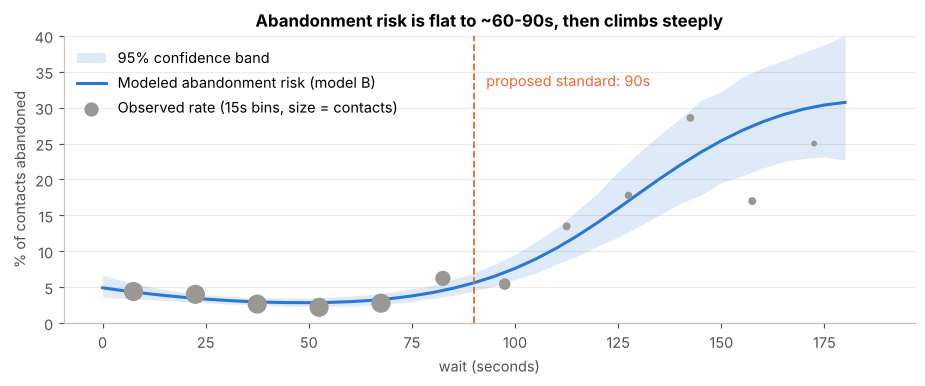

,wait_seconds,p,lo,hi
6,30,0.032,0.027,0.037
12,60,0.030,0.024,0.038
18,90,0.056,0.045,0.070
24,120,0.140,0.107,0.181
30,150,0.254,0.196,0.322
36,180,0.307,0.227,0.401


In [4]:
final = smf.logit(FORMULAS["B  Wait spline only"], data=df).fit(disp=0, maxiter=200)
robust = smf.logit(FORMULAS["C  Wait spline + context + hot-spot x period"], data=df).fit(disp=0, maxiter=200)

grid = pd.DataFrame({"wait_seconds": np.arange(0, 181, 5)})   # plotted only where data is dense; beyond ~180s the spline is unreliable
pred = final.get_prediction(grid).summary_frame(alpha=0.05)
grid["p"], grid["lo"], grid["hi"] = pred["predicted"], pred["ci_lower"], pred["ci_upper"]

# Corroborate the threshold with the simplest possible model: a one-split decision tree
stump = DecisionTreeClassifier(max_depth=1, class_weight="balanced").fit(df[["wait_seconds"]], df.is_abandoned)
split = stump.tree_.threshold[0]
first_over_10 = grid.loc[grid.p >= 0.10, "wait_seconds"].min()
print(f"Decision-stump split on wait: {split:.0f}s | modeled risk first exceeds 10% at ~{first_over_10}s")

emp = df.assign(b=(df.wait_seconds // 15) * 15).groupby("b").agg(n=("is_abandoned", "size"), rate=("is_abandoned", "mean"))
emp = emp[emp.n >= 15]
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.fill_between(grid.wait_seconds, grid.lo * 100, grid.hi * 100, color=BLUE, alpha=0.15, lw=0, label="95% confidence band")
ax.plot(grid.wait_seconds, grid.p * 100, color=BLUE, label="Modeled abandonment risk (model B)")
ax.scatter(emp.index + 7.5, emp.rate * 100, s=emp.n.clip(15, 400) / 3, color=GRAY, zorder=3,
           label="Observed rate (15s bins, size = contacts)")
ax.axvline(90, color=ORANGE, ls="--", lw=1.2); ax.text(93, 33, "proposed standard: 90s", color=ORANGE)
ax.set_xlabel("wait (seconds)"); ax.set_ylabel("% of contacts abandoned"); ax.set_ylim(0, 40)
ax.set_title("Abandonment risk is flat to ~60-90s, then climbs steeply")
ax.legend(frameon=False, loc="upper left"); fig.tight_layout()
fig.savefig(FIG / "py2_abandonment_risk_curve.png", dpi=150, metadata={"Software": None}); plt.show()
grid.loc[grid.wait_seconds.isin([30, 60, 90, 120, 150, 180]), ["wait_seconds", "p", "lo", "hi"]].round(3)

Risk is about 3% up to 60s, about 5.6% at 90s, about 14% at 120s and about 25% at 150s. The one-split tree independently puts the break at about 112s. **90s** is the last point before the curve turns sharply upward, so it is the proposed standard: it leaves a buffer below the ~110–120s break.

## 4 · Calibration: are the predicted probabilities trustworthy?

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
oof = pd.Series(index=df.index, dtype=float)
for tr, te in skf.split(df, df.is_abandoned):
    m = smf.logit(FORMULAS["C  Wait spline + context + hot-spot x period"], data=df.iloc[tr]).fit(disp=0, maxiter=200)
    oof.iloc[te] = m.predict(df.iloc[te]).values
cal = (pd.DataFrame({"p": oof, "y": df.is_abandoned})
         .assign(decile=lambda x: pd.qcut(x.p.rank(method="first"), 10, labels=range(1, 11)))
         .groupby("decile", observed=True).agg(contacts=("y", "size"), predicted=("p", "mean"), observed=("y", "mean")))
display(cal.round(3))
print(f"Out-of-fold AUC {roc_auc_score(df.is_abandoned, oof):.3f}; top-decile observed rate "
      f"{cal.observed.iloc[-1]:.1%} vs bottom-9-decile average {cal.observed.iloc[:-1].mean():.1%}")

,contacts,predicted,observed
decile,,,
1,399,0.014,0.030
2,398,0.020,0.028
3,399,0.024,0.043
4,398,0.028,0.035
5,399,0.031,0.033
6,398,0.036,0.040
7,398,0.041,0.025
8,399,0.048,0.045
9,398,0.061,0.040


Out-of-fold AUC 0.649; top-decile observed rate 16.8% vs bottom-9-decile average 3.5%


Predicted and observed rates line up well in the decile that matters (top: 17.9% predicted vs 16.8% observed). The model slightly under-predicts in the lowest deciles (about 1–2% predicted vs about 3% observed), which is acceptable for sizing the long-wait effect. Most of the model's discrimination sits in the top decile (the long-wait contacts). Below that, abandonment is low and close to random, which is expected.

## 5 · The out-of-time test (shows the limitation explicitly)

In [6]:
train, test = df[df.may_jun == 0], df[df.may_jun == 1]
m_oot = smf.logit(FORMULAS["B  Wait spline only"], data=train).fit(disp=0, maxiter=200)
p_oot = m_oot.predict(test)
print(f"Trained on Jan-Apr, tested on May-Jun: AUC {roc_auc_score(test.is_abandoned, p_oot):.3f}; "
      f"mean predicted {p_oot.mean():.1%} vs actual {test.is_abandoned.mean():.1%}")

Trained on Jan-Apr, tested on May-Jun: AUC 0.397; mean predicted 3.5% vs actual 6.9%


A model trained only on Jan–Apr **under-predicts** May–Jun abandonment badly. It never saw waits over 2 minutes, so it extrapolates the flat part of the curve. **Lesson for production:** retrain whenever the wait distribution moves outside the range the model was trained on, and monitor calibration monthly.

## 6 · Business impact: what is holding phone waits under 90s worth?

In [7]:
hs_now = df[(df.hotspot == 1) & (df.may_jun == 1)].copy()
capped = hs_now.assign(wait_seconds=hs_now.wait_seconds.clip(upper=90))
months = 2
rows = []
for label, m in [("Model B (wait only) - central estimate", final),
                 ("Model C (controls for hot-spot x period) - conservative", robust)]:
    now, cap = m.predict(hs_now).sum() / months, m.predict(capped).sum() / months
    rows.append({"model": label, "expected abandoned / month now": now,
                 "with all hot-spot waits <= 90s": cap, "avoided / month": now - cap,
                 "hot-spot abandonment now": m.predict(hs_now).mean(), "hot-spot abandonment at 90s": m.predict(capped).mean()})
impact = pd.DataFrame(rows)
print(f"Actual hot-spot abandoned contacts per month in May-Jun: {hs_now.is_abandoned.sum() / months:.0f}")
impact.to_csv(FIG / "py2_business_impact.csv", index=False)
impact.round(3)

Actual hot-spot abandoned contacts per month in May-Jun: 31


,model,expected abandoned / month now,with all hot-spot waits <= 90s,avoided / month,hot-spot abandonment now,hot-spot abandonment at 90s
0,Model B (wait only) - central estimate,28.109,7.857,20.252,0.193,0.054
1,Model C (controls for hot-spot x period) - con...,31.000,15.655,15.345,0.213,0.108


Holding hot-spot waits at or under 90s is expected to avoid about **15–20 abandoned contacts a month** in that queue, about half to two-thirds of the current ~31. Hot-spot abandonment would fall from about 20% to about 5–11%. The conservative model gives the low end because it assumes part of the excess comes from the queue itself and not only from the wait.

## 7 · Decision and limitations

**Would I use this for a business decision?** Yes, for **setting the phone wait standard and sizing the benefit**. No, for predicting individual callers (AUC about 0.65 is too weak for that).

- **Use:** add a service-level standard such as *"at least 90% of phone contacts answered within 90 seconds"* alongside the average-wait KPI. The 65s average target hid a tail where 68% of hot-spot callers waited more than 2 minutes. The model estimates that holding hot-spot waits at or under 90s avoids about 15–20 of the ~31 abandoned contacts a month in that queue.
- **Don't use:** for routing or interventions on individual callers. Discrimination is modest, and the signal is in the wait, which you control by staffing, not by prediction.

**Limitations.**
- Synthetic data; associations only. Timing, dose-response and robustness to controls support a causal reading, but a staffing change, or the A/B test of a callback offer, would be the real proof.
- For abandoned contacts, recorded wait may be the time until the caller hung up (right-censored). This would *understate* their true wait and make the threshold look later than it is. 90s is therefore a cautious standard.
- The model only covers waits seen in the data. Few contacts waited more than 180s, so the curve is shown only up to 180s; beyond that the spline is unreliable.
- It does not price the cost of abandonment (callbacks, attrition). Those need data we do not have (see the memo, I-4).